# Backtracking y el recorrido del caballo

**Inteligencia Artificial · IS784 · Taller de laboratorio**

Un caballo debe visitar cada casilla del tablero exactamente una vez. Puede terminar en cualquier casilla en un **recorrido abierto**. Para un **recorrido cerrado**, además debe poder saltar de la última casilla a la inicial. En este taller, «abierto» significa que no se exige el salto de regreso.

**Objetivos**

- Representar una solución parcial y formular el caso base de una búsqueda recursiva.
- Explicar qué debe restaurarse al abandonar una rama.
- Implementar, probar y animar un solucionador propio.
- Medir el efecto del orden de exploración sobre el trabajo de la búsqueda.

Las coordenadas son pares `(fila, columna)` numerados desde cero. La fila crece hacia abajo. Un salto legal cumple `(|Δfila|, |Δcolumna|) = (1, 2)` o `(2, 1)`. Por ejemplo, desde `(0, 0)` se puede ir a `(1, 2)` o a `(2, 1)`.

Ejecute las celdas en orden con Python 3. La animación ya está incluida en el cuaderno. Para regenerarla se necesitan Pillow y Matplotlib. Si faltan en su entorno de Jupyter, ejecute `%pip install pillow matplotlib` en una celda y vuelva a ejecutar el cuaderno.

## 1. Elegir, explorar y deshacer

Cada nodo del árbol de búsqueda representa un **camino parcial**. Sus hijos corresponden a saltos legales que aún no aparecen en ese camino. Una misma posición puede aparecer en diferentes ramas porque las demás casillas visitadas pueden ser distintas.

Conserve dos estructuras: `camino`, que guarda el orden de los saltos, y `visitadas`, que permite comprobar la pertenencia con un conjunto. Justo antes y después de explorar una rama fallida debe mantenerse el invariante `visitadas == set(camino)`. Al volver de esa rama se debe haber recuperado exactamente el camino anterior, en el mismo orden.

```text
BUSCAR
    si el camino ocupa todas las casillas:
        devolver si cumple la condición del recorrido

    para cada destino legal y libre desde la última casilla:
        agregar el destino al camino y marcarlo como visitado
        si BUSCAR devuelve éxito:
            devolver éxito
        quitar el destino del camino y desmarcarlo

    devolver fracaso
```

Una llamada puede fracasar porque se quedó sin destinos libres o porque agotó todos sus descendientes. Cuando eso ocurre, su llamador deshace el salto que lo llevó allí y prueba la siguiente alternativa. Si una rama tiene éxito, las llamadas retornan conservando el camino completo.

Con `N` casillas, la pila recursiva puede alcanzar profundidad `N`. Un límite superior grueso para el árbol es `O(8^N)`; las restricciones reducen la cantidad de ramas efectivas. El camino, el conjunto y la pila usan `O(N)` de espacio. Guardar todos los eventos de animación añade espacio lineal en el número de eventos registrados.

## 2. Observe un retroceso

La traza se grabó en un tablero **5×5**, desde **(0, 0)**, con un orden fijo de movimientos escogido para que se vean varios retrocesos en poco tiempo. El verde señala un avance. En naranja, el caballo queda en la casilla a la que volvió y el aspa marca la casilla que acaba de liberar. Los números muestran la posición de cada casilla en el camino actual. La animación se repite automáticamente.

Antes de verla, prediga qué ocurre con el último número del tablero cuando el caballo retrocede. Después, use el visor de fotogramas para comprobar su predicción.

In [ ]:
TRAZA_DEMO = [('inicio', 0, 0), ('avance', 1, 2), ('avance', 0, 4), ('avance', 2, 3), ('avance', 4, 4), ('avance', 3, 2), ('avance', 2, 4), ('avance', 4, 3), ('avance', 3, 1), ('avance', 1, 0), ('avance', 0, 2), ('avance', 1, 4), ('avance', 3, 3), ('avance', 4, 1), ('avance', 2, 0), ('avance', 0, 1), ('avance', 1, 3), ('avance', 3, 4), ('avance', 4, 2), ('avance', 3, 0), ('avance', 2, 2), ('avance', 0, 3), ('avance', 1, 1), ('retroceso', 1, 1), ('retroceso', 0, 3), ('retroceso', 2, 2), ('avance', 1, 1), ('avance', 0, 3), ('avance', 2, 2), ('retroceso', 2, 2), ('retroceso', 0, 3), ('retroceso', 1, 1), ('retroceso', 3, 0), ('avance', 2, 1), ('avance', 4, 0), ('retroceso', 4, 0), ('retroceso', 2, 1), ('retroceso', 4, 2), ('avance', 2, 2), ('avance', 3, 0), ('avance', 4, 2), ('avance', 2, 1), ('avance', 4, 0), ('retroceso', 4, 0), ('retroceso', 2, 1), ('retroceso', 4, 2), ('avance', 1, 1), ('avance', 0, 3), ('retroceso', 0, 3), ('retroceso', 1, 1), ('retroceso', 3, 0), ('avance', 0, 3), ('avance', 1, 1), ('avance', 3, 0), ('avance', 4, 2), ('avance', 2, 1), ('avance', 4, 0), ('éxito', 4, 0)]

In [ ]:
from io import BytesIO

from IPython.display import Image as NotebookImage, display
from matplotlib import get_data_path
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont

FONT_DIR = Path(get_data_path()) / "fonts" / "ttf"
FONT = FONT_DIR / "DejaVuSans.ttf"
TEXT_FONT = ImageFont.truetype(str(FONT), 17)
TITLE_FONT = ImageFont.truetype(str(FONT), 20)
HORSE_FONT = ImageFont.truetype(str(FONT), 31)

LABELS = {
    "inicio": "Inicio", "avance": "Avance", "retroceso": "Retroceso",
    "éxito": "Recorrido completo", "fracaso": "Búsqueda agotada",
    "límite": "Presupuesto agotado",
}


def dibujar_fotograma(n, camino, evento, indice):
    """Dibuja el camino después de aplicar el evento."""
    paso = min(60, 380 // n)
    margen_x, margen_y = 40, 66
    ancho = n * paso
    fondo = Image.new("RGB", (max(415, ancho + 66), ancho + 117), "#f8fafc")
    draw = ImageDraw.Draw(fondo)
    tipo, fila, columna = evento
    color = "#b45309" if tipo == "retroceso" else "#047857"
    draw.text((16, 11), f"{indice:02d} · {LABELS[tipo]}", font=TITLE_FONT,
              fill=color if tipo in {"avance", "retroceso", "éxito"} else "#0f172a")

    def esquina(f, c):
        return margen_x + c * paso, margen_y + f * paso

    for f in range(n):
        draw.text((19, margen_y + f * paso + paso / 2), str(f), font=TEXT_FONT,
                  anchor="mm", fill="#334155")
        draw.text((margen_x + f * paso + paso / 2, 52), str(f), font=TEXT_FONT,
                  anchor="mm", fill="#334155")
        for c in range(n):
            x, y = esquina(f, c)
            base = "#e2e8f0" if (f + c) % 2 == 0 else "#b8cadb"
            draw.rectangle((x, y, x + paso - 1, y + paso - 1), fill=base)

    for numero, (f, c) in enumerate(camino, start=1):
        x, y = esquina(f, c)
        actual = numero == len(camino)
        draw.rectangle((x + 2, y + 2, x + paso - 3, y + paso - 3),
                       fill=color if actual else "#d1fae5")
        if actual:
            draw.text((x + paso / 2, y + paso * 0.59), "♞", font=HORSE_FONT,
                      anchor="mm", fill="#ffffff")
            draw.text((x + 5, y + 2), str(numero), font=TEXT_FONT, fill="#ffffff")
        else:
            draw.text((x + paso / 2, y + paso / 2), str(numero), font=TEXT_FONT,
                      anchor="mm", fill="#064e3b")

    if tipo == "retroceso":
        x, y = esquina(fila, columna)
        draw.rectangle((x + 3, y + 3, x + paso - 4, y + paso - 4),
                       outline=color, width=3)
        draw.text((x + paso / 2, y + paso / 2), "×", font=HORSE_FONT,
                  anchor="mm", fill=color)

    draw.text((16, margen_y + ancho + 14),
              f"Visitadas {len(camino)}/{n*n} · Evento en ({fila}, {columna})",
              font=TEXT_FONT, fill="#0f172a")
    return fondo


def fotogramas(n, traza):
    """Reproduce eventos ya registrados; la búsqueda ocurre por separado."""
    camino = []
    for indice, evento in enumerate(traza):
        tipo, fila, columna = evento
        casilla = (fila, columna)
        if tipo in {"inicio", "avance"}:
            camino.append(casilla)
        elif tipo == "retroceso":
            if len(camino) < 2 or camino[-1] != casilla:
                raise ValueError(f"Retroceso incoherente en el evento {indice}")
            camino.pop()
        yield dibujar_fotograma(n, camino, evento, indice)


def gif_traza(n, traza):
    cuadros = list(fotogramas(n, traza))
    duraciones = [650 if evento[0] == "retroceso" else 280 for evento in traza]
    duraciones[0] = 950
    duraciones[-1] = 2200
    archivo = BytesIO()
    cuadros[0].save(archivo, format="GIF", save_all=True, append_images=cuadros[1:],
                    duration=duraciones, loop=0)
    return archivo.getvalue()

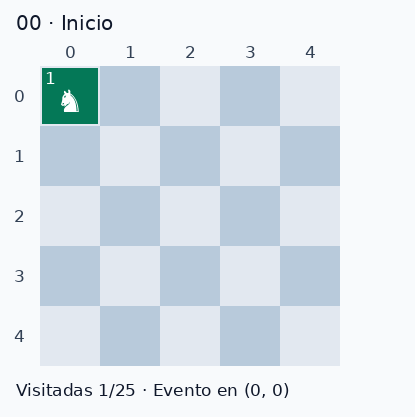

In [ ]:
gif_demo = gif_traza(5, TRAZA_DEMO)
salida_gif = gif_demo, "image/gif"
display(NotebookImage(data=gif_demo, format="gif"))

### Laboratorio de observación

1. Seleccione el primer fotograma de retroceso. Registre las coordenadas de la casilla liberada y de la casilla a la que vuelve el caballo. ¿Cuántas casillas están visitadas antes y después?
2. Dibuje la pila de llamadas para los últimos tres niveles justo antes y después de ese retroceso. Localice el marco que elige el siguiente destino.
3. Encuentre en la traza una casilla que se libera y más tarde vuelve a aparecer como destino. Explique por qué esa segunda visita es válida.

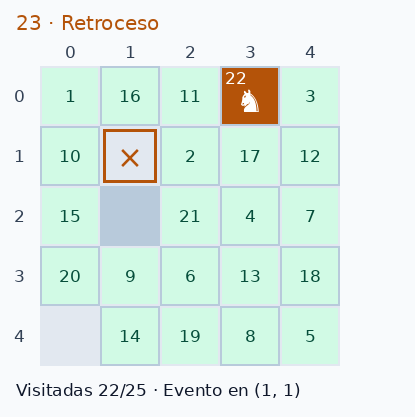

In [ ]:
from itertools import islice


def ver_fotograma(n, traza, indice):
    if not 0 <= indice < len(traza):
        raise IndexError(f"Use un índice entre 0 y {len(traza) - 1}")
    cuadro = next(islice(fotogramas(n, traza), indice, None))
    archivo = BytesIO()
    cuadro.save(archivo, format="PNG")
    return archivo.getvalue()


indice = next(i for i, evento in enumerate(TRAZA_DEMO) if evento[0] == "retroceso")
# Cambie indice por indice - 1 o indice + 1 para comparar.
imagen_paso = ver_fotograma(5, TRAZA_DEMO, indice)
salida_paso = imagen_paso, "image/png"
display(NotebookImage(data=imagen_paso, format="png"))

## 3. Implemente su solucionador

### Reto 1 · Genere saltos legales

Complete `saltos_legales`. Use los ocho desplazamientos, compruebe los límites y descarte toda casilla de `visitadas`. Conserve el orden de entrada. Compruebe a mano los casos de una esquina, una casilla central y un tablero pequeño donde no cabe ningún salto.

### Reto 2 · Construya la búsqueda recursiva

Complete `resolver` para recorridos abiertos y pruebe primero con tableros de 1×1, 3×3 y 5×5. Use un conjunto para las visitadas y deje el registro de eventos bajo el control de las operaciones que modifican el camino. Elija una rama fallida de su propia ejecución y compruebe el invariante antes y después de explorarla.

**Contrato**

- `resolver` recibe `n` entero positivo, un inicio dentro del tablero, una permutación de `DESPLAZAMIENTOS`, y una estrategia `"fijo"` o `"warnsdorff"`. El presupuesto es un entero positivo.
- Devuelve `(estado, camino, traza, expansiones)`. Los estados son `"éxito"`, `"fracaso"` y `"límite"`. Devuelva una lista de coordenadas para el camino exitoso y `None` en los otros dos estados.
- Cuente una expansión cada vez que entra a procesar un camino parcial, incluida la raíz y los casos base. Si queda un destino por explorar y no hay presupuesto para procesarlo, devuelva límite antes de registrar ese avance. Una llamada ya contabilizada puede reconocer un caso base exitoso aunque consuma la última expansión.
- La traza empieza con `("inicio", fila, columna)`. Un avance identifica la casilla agregada. Un retroceso identifica la casilla retirada, incluso si la búsqueda está desenrollando la pila tras alcanzar el presupuesto. El último evento usa el estado de retorno y las coordenadas donde quedó el camino tras el desenrollado.
- Si se agota el presupuesto, propague ese estado hasta la raíz. Si se agota todo el árbol, devuelva fracaso. La raíz conserva la casilla inicial en ambos casos.
- Puede registrar una ejecución corta para el GIF y usar trazas largas solo para contar eventos o inspeccionar fotogramas puntuales.

In [ ]:
DESPLAZAMIENTOS = (
    (-1, 2), (1, 2), (2, 1), (2, -1),
    (1, -2), (-1, -2), (-2, -1), (-2, 1),
)


def saltos_legales(n, posicion, visitadas, orden):
    """Devuelve las casillas libres alcanzables, en el orden recibido."""
    raise NotImplementedError("Reto 1")


def resolver(n, inicio, *, orden=DESPLAZAMIENTOS, estrategia="fijo",
             cerrado=False, presupuesto=50_000):
    """Devuelve estado, camino, traza y número de expansiones."""
    # Inicialice el camino y las visitadas.
    # Defina la función recursiva y ubique el caso base.
    # Registre los cambios de estado y pruebe las ramas candidatas.
    raise NotImplementedError("Retos 2 y 3")

### Reto 3 · Compare estrategias y exija cierre

1. En `"fijo"`, use el orden recibido. En `"warnsdorff"`, pruebe primero el destino con menos saltos libres **desde ese destino**, tratando ese destino como visitado. Para empates conserve el orden recibido. Mantenga el retroceso con ambas estrategias, incluso cuando la primera opción heurística falle.
2. Implemente el modo cerrado. Cuando el camino cubra todo el tablero, compruebe si el caballo puede regresar al inicio con un salto. Si no puede, explore otras ramas. Para el chequeo de cierre, considere la geometría del salto aunque el inicio ya esté visitado.
3. Explique con un tablero bicolor por qué un recorrido cerrado en un tablero impar por impar es imposible. Cada salto cambia de color y el camino cerrado tendría `n²` saltos contando el regreso. Use el caso de 1×1 cerrado para probar el retorno sin éxito.
4. Compare las estrategias con el mismo presupuesto y orden de desempate. Informe el estado, las expansiones y los retrocesos. Si una ejecución termina por presupuesto, consérvela en la tabla como **límite**.

| Tablero | Inicio | Modo | Estrategia | Estado | Expansiones | Retrocesos |
|---|---|---|---|---|---:|---:|
| 5×5 | (0, 0) | Abierto | Fijo | | | |
| 5×5 | (0, 0) | Abierto | Warnsdorff | | | |
| Asignado | Asignado | Abierto | Fijo | | | |
| Asignado | Asignado | Abierto | Warnsdorff | | | |

In [ ]:
def es_salto(a, b):
    return sorted((abs(a[0] - b[0]), abs(a[1] - b[1]))) == [1, 2]


def recorrido_valido(n, inicio, camino, *, cerrado=False):
    if not camino or len(camino) != n * n or camino[0] != inicio:
        return False
    return (
        len(set(camino)) == len(camino)
        and all(0 <= f < n and 0 <= c < n for f, c in camino)
        and all(es_salto(a, b) for a, b in zip(camino, camino[1:]))
        and (not cerrado or es_salto(camino[-1], inicio))
    )


def probar_saltos():
    assert saltos_legales(5, (0, 0), {(0, 0)}, DESPLAZAMIENTOS) == [(1, 2), (2, 1)]
    assert saltos_legales(5, (0, 0), {(0, 0), (1, 2)}, DESPLAZAMIENTOS) == [(2, 1)]
    assert len(saltos_legales(5, (2, 2), {(2, 2)}, DESPLAZAMIENTOS)) == 8
    assert saltos_legales(2, (0, 0), {(0, 0)}, DESPLAZAMIENTOS) == []


def probar_resolver():
    estado, camino, _, expansiones = resolver(1, (0, 0), presupuesto=1)
    assert (estado, camino, expansiones) == ("éxito", [(0, 0)], 1)

    estado, camino, traza, expansiones = resolver(5, (0, 0), presupuesto=1)
    assert (estado, camino, expansiones) == ("límite", None, 1)
    assert traza == [("inicio", 0, 0), ("límite", 0, 0)]

    estado, camino, traza, expansiones = resolver(5, (0, 0), presupuesto=2)
    assert (estado, camino, expansiones) == ("límite", None, 2)
    assert [tipo for tipo, _, _ in traza] == ["inicio", "avance", "retroceso", "límite"]

    estado, camino, _, _ = resolver(3, (0, 0))
    assert (estado, camino) == ("fracaso", None)

    estado, camino, _, _ = resolver(1, (0, 0), cerrado=True)
    assert (estado, camino) == ("fracaso", None)

    for estrategia in ("fijo", "warnsdorff"):
        estado, camino, traza, _ = resolver(5, (0, 0), estrategia=estrategia)
        assert estado == "éxito" and recorrido_valido(5, (0, 0), camino)
        assert traza[-1] == ("éxito", *camino[-1])

# Quite el comentario cuando termine cada reto.
# probar_saltos()
# probar_resolver()

### Reto 4 · Anime y sustente su propia ejecución

- Conecte la traza de su solucionador con `gif_traza`. Elija un tramo que muestre una rama fallida y describa qué casilla se libera, dónde queda el caballo y cuál será la siguiente alternativa según su orden de saltos.
- Si la traza es larga, muestre los fotogramas alrededor de un retroceso con `ver_fotograma`. Para un GIF corto con contexto, pase un **prefijo** de la traza que empiece en el evento inicial.
- En clase, el docente asignará a cada equipo un caso con tablero de 5×5 o 6×6, una casilla inicial y una rotación de la lista de desplazamientos. Conserve esas condiciones para comparar estrategias. Documente un cambio en otro parámetro y prediga su efecto antes de ejecutar.

## 4. Evidencia y evaluación

El taller se puede hacer con IA declarada. Durante el laboratorio, cada integrante reconstruirá a mano un fragmento de la traza y explicará una decisión de implementación. En la sustentación, el docente cambiará un dato de entrada o el orden de dos saltos. Antes de correr el código, cada estudiante deberá anticipar un efecto verificable, como el primer destino, el estado esperado con un presupuesto pequeño o la posibilidad de un circuito cerrado.

Entreguen el cuaderno ejecutado, con la traza manual anotada, el código propio, la tabla comparativa y el fotograma o GIF comentado. Incluyan una prueba adicional que hubiera detectado un error de su implementación y expliquen qué comprueba.

| Criterio | Peso |
|---|---:|
| Saltos legales, caso base y restauración del estado | 35 % |
| Pruebas y demostración de las tres salidas de búsqueda | 20 % |
| Comparación reproducible de estrategias y explicación del cierre | 20 % |
| Animación de la ejecución propia y sustentación individual | 25 % |